In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import mean_squared_error, r2_score


In [2]:
df = pd.read_csv("taxi_trip_pricing.csv")


In [3]:
df = df.dropna(subset=["Trip_Price"]).copy()


In [4]:
numeric_cols = df.select_dtypes(include=["number"]).columns
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical features with their most common value
categorical_cols = df.select_dtypes(include=["object"]).columns

for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])



In [5]:
X = df.drop("Trip_Price", axis=1)
y = df["Trip_Price"]


In [6]:
X = pd.get_dummies(X, drop_first=True, dtype=int)


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [8]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [9]:
poly = PolynomialFeatures(degree=3, include_bias=False)

X_train_poly = poly.fit_transform(X_train_scaled)
X_test_poly = poly.transform(X_test_scaled)



In [10]:
poly_scaler = StandardScaler()

X_train_poly = poly_scaler.fit_transform(X_train_poly)
X_test_poly = poly_scaler.transform(X_test_poly)


In [11]:
y_scaler = StandardScaler()

y_train_scaled = y_scaler.fit_transform(
    y_train.to_numpy().reshape(-1, 1)
).ravel()

In [12]:
# Train Polynomial Regression using Gradient Descent with Momentum
# Momentum uses part of the previous update to help guide the next update.

X_train_momentum = np.column_stack((np.ones(len(X_train_poly)), X_train_poly))
X_test_momentum = np.column_stack((np.ones(len(X_test_poly)), X_test_poly))

weights_momentum = np.zeros(X_train_momentum.shape[1])

learning_rate = 0.001
momentum = 0.9
epochs = 100

velocity = np.zeros_like(weights_momentum)

for epoch in range(epochs):
    # Full-batch Gradient Descent: use all training examples for each update
    predictions = X_train_momentum @ weights_momentum
    gradient = X_train_momentum.T @ (predictions - y_train_scaled) / len(y_train_scaled)

    # Momentum update
    velocity = momentum * velocity + learning_rate * gradient
    weights_momentum -= velocity

# Predict trip prices on test data
momentum_predictions_scaled = X_test_momentum @ weights_momentum
momentum_predictions = y_scaler.inverse_transform(
    momentum_predictions_scaled.reshape(-1, 1)
).ravel()

print("Gradient Descent with Momentum Results")
print("MSE:", mean_squared_error(y_test, momentum_predictions))
print("R2 Score:", r2_score(y_test, momentum_predictions))


Gradient Descent with Momentum Results
MSE: 546.1600672739773
R2 Score: 0.7663365243056988


In [13]:
# Full-batch Gradient Descent with Momentum:
# - Uses the entire training dataset for each weight update.
# - momentum = 0.9 keeps 90% of the previous velocity in each update.


In [14]:
print("Gradient Descent with Momentum Results")
print("MSE:", mean_squared_error(y_test, momentum_predictions))
print("R2 Score:", r2_score(y_test, momentum_predictions))


Gradient Descent with Momentum Results
MSE: 546.1600672739773
R2 Score: 0.7663365243056988


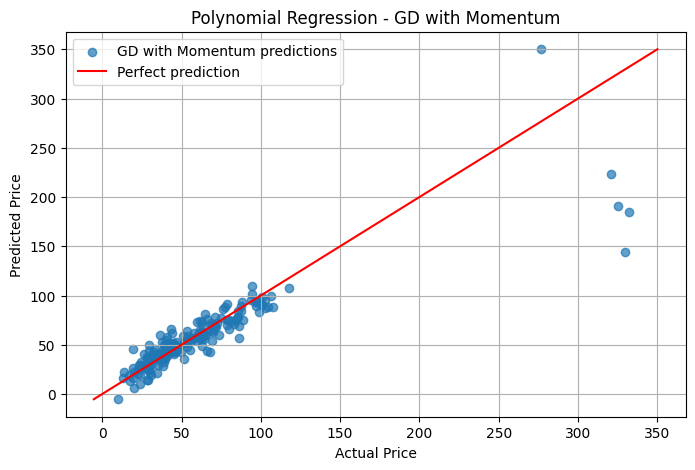

In [15]:
import matplotlib.pyplot as plt

# Actual vs predicted prices for Gradient Descent with Momentum
plt.figure(figsize=(8, 5))
plt.scatter(y_test, momentum_predictions, alpha=0.7,
            label="GD with Momentum predictions")

minimum = min(y_test.min(), momentum_predictions.min())
maximum = max(y_test.max(), momentum_predictions.max())
plt.plot([minimum, maximum], [minimum, maximum], color="red",
         label="Perfect prediction")

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Polynomial Regression - GD with Momentum")
plt.legend()
plt.grid(True)
plt.show()


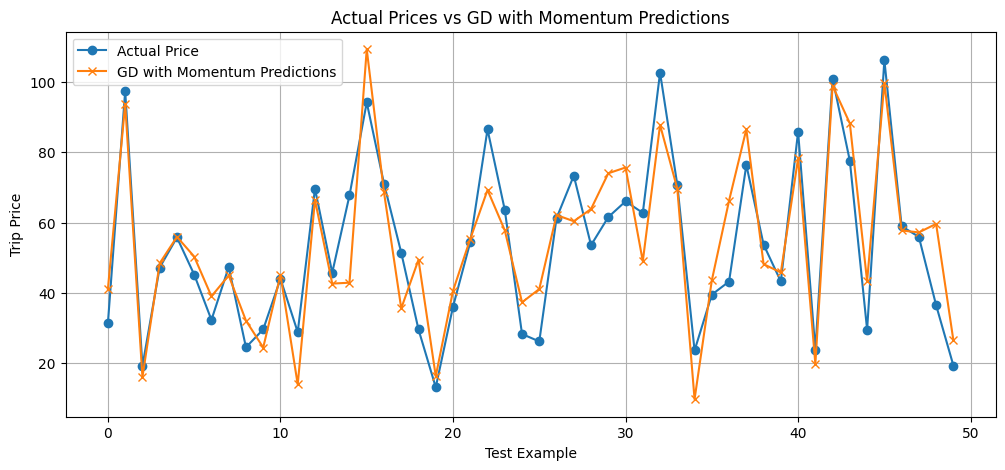

In [16]:
# Show the first 50 test examples
plt.figure(figsize=(12, 5))

plt.plot(np.array(y_test)[:50], marker="o", label="Actual Price")
plt.plot(momentum_predictions[:50], marker="x",
         label="GD with Momentum Predictions")

plt.xlabel("Test Example")
plt.ylabel("Trip Price")
plt.title("Actual Prices vs GD with Momentum Predictions")
plt.legend()
plt.grid(True)
plt.show()


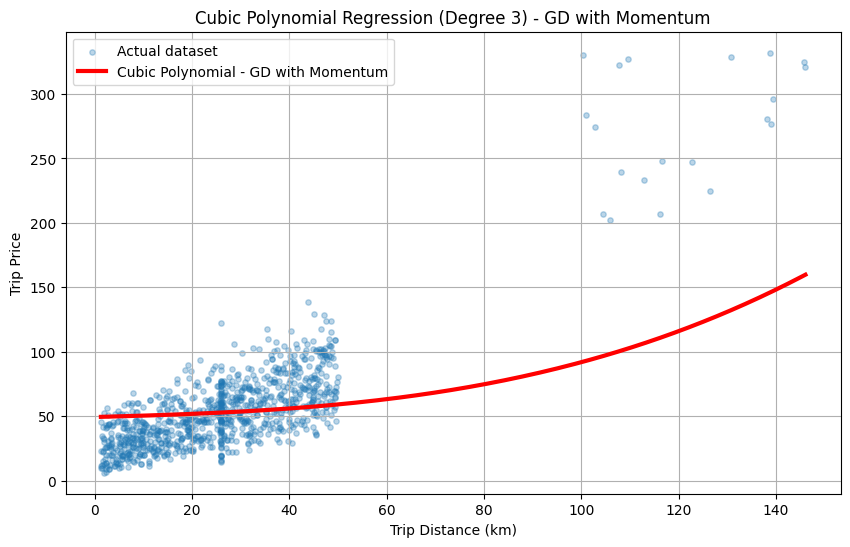

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Choose one feature for the x-axis
feature = "Trip_Distance_km"

# Create evenly spaced distances for a smooth curve
x_curve = np.linspace(X[feature].min(), X[feature].max(), 200)

# Start with all features at their average values
X_curve = pd.DataFrame([X.mean(numeric_only=True).to_dict()] * len(x_curve))

# Keep the same columns and vary only trip distance
X_curve[feature] = x_curve
X_curve = X_curve[X.columns]

# Apply the same preprocessing used during training
X_curve_scaled = scaler.transform(X_curve)
X_curve_poly = poly.transform(X_curve_scaled)
X_curve_poly = poly_scaler.transform(X_curve_poly)

# Predict with Gradient Descent with Momentum
X_curve_momentum = np.column_stack((np.ones(len(X_curve_poly)), X_curve_poly))
y_momentum_curve = y_scaler.inverse_transform(
    (X_curve_momentum @ weights_momentum).reshape(-1, 1)
).ravel()

# Plot the original dataset and momentum curve
plt.figure(figsize=(10, 6))
plt.scatter(X[feature], y, alpha=0.3, s=15, label="Actual dataset")
plt.plot(x_curve, y_momentum_curve, color="red", linewidth=3,
         label="Cubic Polynomial - GD with Momentum")

plt.xlabel("Trip Distance (km)")
plt.ylabel("Trip Price")
plt.title("Cubic Polynomial Regression (Degree 3) - GD with Momentum")
plt.legend()
plt.grid(True)
plt.show()


In [18]:
from sklearn.metrics import mean_squared_error, r2_score

momentum_mse = mean_squared_error(y_test, momentum_predictions)
momentum_r2 = r2_score(y_test, momentum_predictions)

print("===== GD WITH MOMENTUM RESULTS =====")
print("MSE:", round(momentum_mse, 2))
print("R2 Score:", round(momentum_r2, 4))
print("Learning rate:", learning_rate)
print("Momentum:", momentum)


===== GD WITH MOMENTUM RESULTS =====
MSE: 546.16
R2 Score: 0.7663
Learning rate: 0.001
Momentum: 0.9
